# 1.Import the Packages:

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from datetime import datetime
import seaborn as sns

# 2. Read CSV File:

In [3]:
df=pd.read_csv("D:/DS Course/Food_Delivery_P2/Online_Food_Delivery_Analysis.csv")

# 3. Data Inspection:

In [4]:
df.shape

(100000, 25)

In [5]:
df.head(3)

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19.0,Male,NaN,Central,RES936,Restaurant_29,Chinese,10/20/2024,...,NaN,UPI,Delivered,NaN,DP563,5.0,4.4,Weekend,True,0.13
1,ORD000002,CUST6515,NaN,Female,Chennai,North,RES689,Restaurant_419,Chinese,8/12/2024,...,4849.0,COD,Delivered,NaN,DP369,5.0,4.7,Weekday,True,0.48
2,ORD000003,CUST1765,NaN,Male,Delhi,NaN,RES723,Restaurant_244,Arabian,12/8/2024,...,737.0,Wallet,Delivered,NaN,DP580,4.0,4.9,Weekend,True,0.08


In [6]:
# To Display all COLUMNS:
pd.set_option('display.max_columns',None)

In [7]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Order_Time', 'Delivery_Time_Min', 'Distance_km',
       'Order_Value', 'Discount_Applied', 'Final_Amount', 'Payment_Mode',
       'Order_Status', 'Cancellation_Reason', 'Delivery_Partner_ID',
       'Delivery_Rating', 'Restaurant_Rating', 'Order_Day', 'Peak_Hour',
       'Profit_Margin'],
      dtype='str')

# 4. Data Cleaning:

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Order_ID             100000 non-null  str    
 1   Customer_ID          100000 non-null  str    
 2   Customer_Age         49907 non-null   float64
 3   Customer_Gender      75144 non-null   str    
 4   City                 83274 non-null   str    
 5   Area                 83315 non-null   str    
 6   Restaurant_ID        100000 non-null  str    
 7   Restaurant_Name      100000 non-null  str    
 8   Cuisine_Type         83115 non-null   str    
 9   Order_Date           98986 non-null   str    
 10  Order_Time           98002 non-null   str    
 11  Delivery_Time_Min    66641 non-null   float64
 12  Distance_km          66530 non-null   float64
 13  Order_Value          66673 non-null   float64
 14  Discount_Applied     83285 non-null   float64
 15  Final_Amount         44303 no

# Check Duplicates:

In [9]:
# Copy:
df1=df.copy()
df1.head()


,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,Order_Time,Delivery_Time_Min,Distance_km,Order_Value,Discount_Applied,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19.0,Male,NaN,Central,RES936,Restaurant_29,Chinese,10/20/2024,0:00,187.0,15.75,NaN,NaN,NaN,UPI,Delivered,NaN,DP563,5.0,4.4,Weekend,True,0.13
1,ORD000002,CUST6515,NaN,Female,Chennai,North,RES689,Restaurant_419,Chinese,8/12/2024,0:00,20.0,29.50,4869.0,20.0,4849.0,COD,Delivered,NaN,DP369,5.0,4.7,Weekday,True,0.48
2,ORD000003,CUST1765,NaN,Male,Delhi,NaN,RES723,Restaurant_244,Arabian,12/8/2024,0:00,207.0,NaN,757.0,20.0,737.0,Wallet,Delivered,NaN,DP580,4.0,4.9,Weekend,True,0.08
3,ORD000004,CUST2744,NaN,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,10/8/2024,0:00,143.0,15.68,NaN,NaN,NaN,UPI,Cancelled,Late Delivery,DP155,2.0,3.4,Weekday,NaN,0.04
4,ORD000005,CUST4389,57.0,Female,Chennai,South,RES419,Restaurant_262,Chinese,2/4/2024,0:00,51.0,9.60,372.0,20.0,352.0,Card,Delivered,NaN,DP728,2.0,4.4,Weekend,False,0.12


# Check Duplicate in row-wise:

In [10]:
df1.duplicated().sum()

np.int64(0)

# Check null values:

In [11]:
# To Show the NULL Column alone:
df1.columns[df1.isna().any()]

Index(['Customer_Age', 'Customer_Gender', 'City', 'Area', 'Cuisine_Type',
       'Order_Date', 'Order_Time', 'Delivery_Time_Min', 'Distance_km',
       'Order_Value', 'Discount_Applied', 'Final_Amount', 'Payment_Mode',
       'Cancellation_Reason', 'Delivery_Rating', 'Peak_Hour'],
      dtype='str')

In [12]:
df1['Customer_Gender'].value_counts()

Customer_Gender
Other     25135
Female    25031
Male      24978
Name: count, dtype: int64

In [3]:
import sys
print(sys.executable)

from sklearn.impute import KNNImputer

print("KNNImputer imported successfully")

d:\DS Course\Food_Delivery_P2\.venv\Scripts\python.exe
KNNImputer imported successfully


In [13]:
# Customer_Age Cleaning: KNN

imputer=KNNImputer(n_neighbors=6)
df1['Customer_Age']=imputer.fit_transform(df1[['Customer_Age']]).astype(int)
df1['Customer_Age'].isna().sum()

np.int64(0)

In [14]:
# Customer_Gender Cleaning Using np:
missing = df1['Customer_Gender'].isnull()

df1.loc[missing, 'Customer_Gender'] = np.random.choice(
    ['Male', 'Female'],
    size=missing.sum()
)
df1['Customer_Gender'].isna().sum()

np.int64(0)

In [15]:
# CITY, AREA, CUISINE_TYPE using MODE:
df1['City']=df1['City'].fillna(df1['City'].mode()[0],inplace=True)
df1['Area']=df1['Area'].fillna(df1['Area'].mode()[0],inplace=True)
df1['Cuisine_Type']=df1['Cuisine_Type'].fillna(df1['Cuisine_Type'].mode()[0],inplace=True)


C:\Users\Dell\AppData\Local\Temp\ipykernel_3604\2734228809.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df1['City']=df1['City'].fillna(df1['City'].mode()[0],inplace=True)
C:\Users\Dell\AppData\Local\Temp\ipykernel_3604\2734228809.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chai

<Axes: >

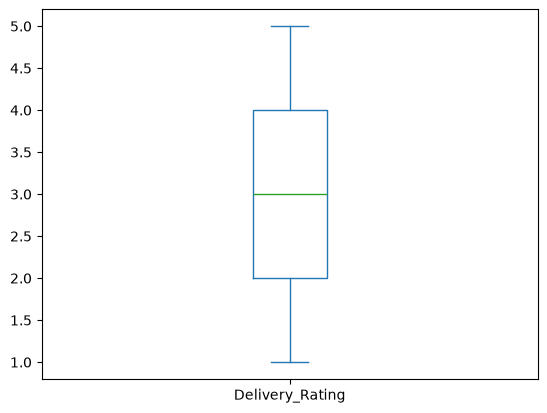

In [16]:
# Check for Delivery_Rating:
df1['Delivery_Rating'].plot(kind='box')

In [ ]:
# Delivery_Rating Fill with MEAdian:
med=df['Delivery_Rating'].median().astype(int)
df1['Delivery_Rating']=df1['Delivery_Rating'].fillna(med)
df1['Delivery_Rating'].isnull().sum()


np.int64(0)

In [18]:
# PAYMENT MODE using MODE:

df1['Payment_Mode']=df1['Payment_Mode'].fillna(df1['Payment_Mode'].mode()[0])

In [19]:
# Cleaning of DATE and TIME Field:
# Order_Time has no values so DROP it:
df1=df1.drop(['Order_Time'],axis=1 )


In [20]:
# DELIVERY TIME MIN Cleaning: 'Order_Date', 'Delivery_Time_Min'
# FIRST covert to DATETIME format:
df1['Order_Date']=pd.to_datetime(df1['Order_Date'],format='mixed')
df1['Delivery_Time_Min']=pd.to_timedelta(df1['Delivery_Time_Min'],unit='m')

In [21]:
df1

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,Delivery_Time_Min,Distance_km,Order_Value,Discount_Applied,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19,Male,Hyderabad,Central,RES936,Restaurant_29,Chinese,2024-10-20,0 days 03:07:00,15.75,NaN,NaN,NaN,UPI,Delivered,NaN,DP563,5.0,4.4,Weekend,True,0.13
1,ORD000002,CUST6515,38,Female,Chennai,North,RES689,Restaurant_419,Chinese,2024-08-12,0 days 00:20:00,29.50,4869.0,20.0,4849.0,COD,Delivered,NaN,DP369,5.0,4.7,Weekday,True,0.48
2,ORD000003,CUST1765,38,Male,Delhi,South,RES723,Restaurant_244,Arabian,2024-12-08,0 days 03:27:00,NaN,757.0,20.0,737.0,Wallet,Delivered,NaN,DP580,4.0,4.9,Weekend,True,0.08
3,ORD000004,CUST2744,38,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,2024-10-08,0 days 02:23:00,15.68,NaN,NaN,NaN,UPI,Cancelled,Late Delivery,DP155,2.0,3.4,Weekday,NaN,0.04
4,ORD000005,CUST4389,57,Female,Chennai,South,RES419,Restaurant_262,Chinese,2024-02-04,0 days 00:51:00,9.60,372.0,20.0,352.0,Card,Delivered,NaN,DP728,2.0,4.4,Weekend,False,0.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,ORD099996,CUST3722,38,Female,Mumbai,South,RES295,Restaurant_500,Arabian,2024-06-10,NaT,NaN,232.0,100.0,132.0,Card,Delivered,NaN,DP835,2.0,4.0,Weekday,True,0.17
99996,ORD099997,CUST6158,38,Male,Mumbai,East,RES157,Restaurant_458,Arabian,2024-04-22,0 days 00:46:00,NaN,1098.0,20.0,1078.0,Card,Delivered,NaN,DP476,4.0,3.5,Weekday,False,-0.15
99997,ORD099998,CUST2155,38,Male,Delhi,East,RES287,Restaurant_273,Indian,2024-02-23,0 days 00:34:00,18.57,NaN,20.0,NaN,COD,Cancelled,NaN,DP577,2.0,4.0,Weekday,True,0.47
99998,ORD099999,CUST3015,38,Female,Delhi,North,RES491,Restaurant_241,Indian,2024-12-10,0 days 01:05:00,3.77,NaN,100.0,NaN,Card,Delivered,NaN,DP896,3.0,4.3,Weekday,NaN,0.44


In [22]:

df1["Delivery_Time"] = df1["Delivery_Time_Min"].astype(str).str[-8:] # this for time delta function
#df1["Delivery_Time_Min"] = df1["Delivery_Time_Min"].dt.strftime("%H:%M:%S") (only for datetime)

# Fill with bfill:
df1["Delivery_Time_Min"]=df1["Delivery_Time_Min"].bfill()
df1["Delivery_Time"]=df1["Delivery_Time"].bfill()

In [23]:
# Clean NULL in Order_Date:
df1['Order_Date']=df1['Order_Date'].bfill() # it show null = 1 so use ffil
df1['Order_Date']=df1['Order_Date'].ffill()
df1['Order_Date'].isnull().sum()

np.int64(0)

In [24]:
df1.columns[df1.isna().any()]

Index(['Distance_km', 'Order_Value', 'Discount_Applied', 'Final_Amount',
       'Cancellation_Reason', 'Peak_Hour'],
      dtype='str')

<Axes: ylabel='Density'>

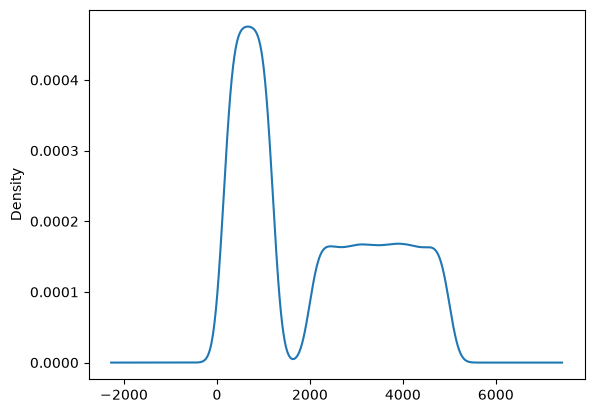

In [25]:
# ORDER_VALUE :
df1['Order_Value'].plot(kind='kde')

In [26]:
# GROUP BY Imputation for Order_Value:
df1['Order_Value'] = df1['Order_Value'].fillna(
    df1.groupby('Cuisine_Type')['Order_Value'].transform('median')
)
df1['Order_Value'].isna().sum()

np.int64(0)

<Axes: ylabel='Density'>

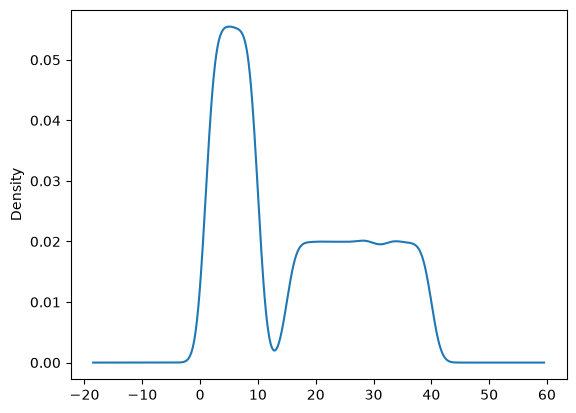

In [27]:
#PLOT for Distance:
df1['Distance_km'].plot(kind='kde')


In [28]:
# IMPUTE distance using MEDIAN:
df1['Distance_km'] = df1['Distance_km'].fillna(
    df1.groupby('City')['Distance_km'].transform('median')
)
df1['Distance_km'].isna().sum()

np.int64(0)

In [29]:
# Discount & Total Amount:
df1['Discount_Applied'] = df1['Discount_Applied'].fillna(
    df1['Order_Value'] - df1['Final_Amount']
)

In [30]:
df1['Discount_Match'] = (
    df1 ['Discount_Applied']== df1['Order_Value'] - df1['Final_Amount']
)

In [31]:
df1['Discount_Applied'].isna().sum() # as final amt is null dis also become null

np.int64(16715)

In [32]:
df1['Final_Amount']=df1['Final_Amount'].fillna(
    df1['Order_Value'] - df1['Discount_Applied']    # both disc & amt null for same row
)
df1['Final_Amount'].isna().sum()

np.int64(16715)

In [33]:
# To Calculate discount for null in two cols:
df1['Discount_Applied'] = df1['Discount_Applied'].fillna(
    df1.groupby('Cuisine_Type')['Discount_Applied'].transform('median')
)
df1['Discount_Applied'].isna().sum()

np.int64(0)

In [34]:
# Find Final_Amt after discount filled with MEDIAN:
df1['Final_Amount']=df1['Final_Amount'].fillna(
    df1['Order_Value'] - df1['Discount_Applied']    # both disc & amt null for same row
)
df1['Final_Amount'].isna().sum()

np.int64(0)

In [35]:
df1['Cancellation_Reason'].value_counts()

Cancellation_Reason
Late Delivery         3059
Customer Cancelled    2993
Restaurant Issue      2979
Name: count, dtype: int64

In [36]:
# CANCELLATION REASON For Delivered customer:
df1.loc[
    df1['Cancellation_Reason'].isna() & 
    (df1['Order_Status'] != 'Cancelled'),
    'Cancellation_Reason'
] = 'Not Applicable'

df1['Cancellation_Reason'].isna().sum()

np.int64(6005)

In [37]:
# CANCELLATION REASON For Order Cancelled Customer: with distance > 10km
df1.loc[
    df1['Cancellation_Reason'].isna() & 
    (df1['Order_Status'] == 'Cancelled') & (df1['Distance_km'] > 10.00),
    'Cancellation_Reason'
] = 'Late Delivery'

In [38]:
# CANCELLATION REASON For Order Cancelled Customer: with RES. Rate <= 2.0
df1.loc[
    df1['Cancellation_Reason'].isna() & 
    (df1['Order_Status'] == 'Cancelled') & (df1['Restaurant_Rating'] <= 2.0),
    'Cancellation_Reason'
] = 'Restaurant Issue'

In [39]:
# CANCELLATION REASON For Order Cancelled Customer: with Customer cancelled themself
df1.loc[
    df1['Cancellation_Reason'].isna() & 
    (df1['Order_Status'] == 'Cancelled'),
    'Cancellation_Reason'
] = 'Customer Cancelled'

In [40]:
df1['Cancellation_Reason'].isna().sum()
df1.columns[df1.isna().any()]

Index(['Peak_Hour'], dtype='str')

In [41]:
df1.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Payment_Mode', 'Order_Status',
       'Cancellation_Reason', 'Delivery_Partner_ID', 'Delivery_Rating',
       'Restaurant_Rating', 'Order_Day', 'Peak_Hour', 'Profit_Margin',
       'Delivery_Time', 'Discount_Match'],
      dtype='str')

In [42]:
# To IMPUTE Peak_ HOUR: Through res_id, order_day
df1[['Restaurant_ID','Peak_Hour','Order_Day']].value_counts()

Restaurant_ID  Peak_Hour  Order_Day
RES237         True       Weekday      53
RES770         False      Weekday      49
RES379         True       Weekday      47
RES462         True       Weekday      46
RES178         False      Weekday      43
                                       ..
RES973         False      Weekend       3
RES823         True       Weekend       3
RES621         False      Weekend       3
RES645         True       Weekend       3
RES920         False      Weekend       1
Name: count, Length: 3599, dtype: int64

In [43]:
df1['Restaurant_ID'].value_counts()

Restaurant_ID
RES509    145
RES591    145
RES271    144
RES910    143
RES237    142
         ... 
RES424     85
RES747     84
RES716     84
RES653     82
RES676     74
Name: count, Length: 900, dtype: int64

In [44]:
pd.crosstab(
    [df1['Restaurant_ID'], df1['Order_Day']],
    df1['Peak_Hour']
)

Peak_Hour                False  True 
Restaurant_ID Order_Day              
RES100        Weekday       20     32
              Weekend        8      8
RES101        Weekday       37     23
              Weekend        9      7
RES102        Weekday       22     32
...                        ...    ...
RES997        Weekend       10      6
RES998        Weekday       16     34
              Weekend        5      9
RES999        Weekday       26     27
              Weekend       12     11

[1800 rows x 2 columns]

In [46]:
peak_rate = (
    df1.groupby(['Restaurant_ID', 'Order_Day'])['Peak_Hour']
    .mean()
    .round(2)
)

In [47]:
peak_rate = (
    df1.groupby(['Restaurant_ID', 'Order_Day'])['Peak_Hour']
    .transform('mean')
    .round(2)
)

df1['Peak_Hour'] = df1['Peak_Hour'].fillna(peak_rate > 0.5)

In [48]:
df1.isna().sum()

Order_ID               0
Customer_ID            0
Customer_Age           0
Customer_Gender        0
City                   0
Area                   0
Restaurant_ID          0
Restaurant_Name        0
Cuisine_Type           0
Order_Date             0
Delivery_Time_Min      0
Distance_km            0
Order_Value            0
Discount_Applied       0
Final_Amount           0
Payment_Mode           0
Order_Status           0
Cancellation_Reason    0
Delivery_Partner_ID    0
Delivery_Rating        0
Restaurant_Rating      0
Order_Day              0
Peak_Hour              0
Profit_Margin          0
Delivery_Time          0
Discount_Match         0
dtype: int64

In [49]:
df1.describe()

,Customer_Age,Order_Date,Delivery_Time_Min,Distance_km,Order_Value,Discount_Applied,Final_Amount,Delivery_Rating,Restaurant_Rating,Profit_Margin
count,100000.000000,100000,100000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000
mean,38.487350,2024-06-30 14:28:07.967999,0 days 02:07:30,14.843622,1921.023590,86.59230,1834.431290,2.992930,4.249680,0.150362
min,18.000000,2024-01-01 00:00:00,0 days 00:20:00,1.000000,150.000000,0.00000,-150.000000,1.000000,3.000000,-0.200000
25%,38.000000,2024-03-31 00:00:00,0 days 00:45:00,7.760000,935.000000,20.00000,847.000000,2.000000,3.600000,-0.020000
50%,38.000000,2024-07-01 00:00:00,0 days 02:00:00,9.940000,1199.000000,50.00000,1197.000000,3.000000,4.200000,0.150000
75%,39.000000,2024-09-30 00:00:00,0 days 03:29:00,21.130000,2743.000000,100.00000,2655.000000,4.000000,4.900000,0.320000
max,60.000000,2024-12-30 00:00:00,0 days 05:00:00,40.000000,5000.000000,300.00000,5000.000000,5.000000,5.500000,0.500000
std,8.753879,NaN,0 days 01:30:45,10.347633,1309.912883,100.10432,1313.602711,1.292013,0.722554,0.201888


# Correcting Invalid Values:

In [50]:
# Final amount has -ve values:
(df1.Final_Amount < 0).sum()

np.int64(773)

In [51]:
# As TOT_AMT is neg NULL the DISCOUNT high than Order_value:
df1.loc[
    df1['Discount_Applied'] > df1['Order_Value'],
    'Discount_Applied'
] = np.nan

In [52]:
df1['Discount_Applied'] = df1['Discount_Applied'].fillna(
    df1['Discount_Applied'].median()
)
df1['Discount_Applied'].isna().sum()

np.int64(0)

In [53]:
df1['Final_Amount'] = (
    df1['Order_Value'] - df1['Discount_Applied']
)
df1['Final_Amount'].isna().sum()

np.int64(0)

In [54]:
(df1.Final_Amount < 0).sum()

np.int64(0)

In [55]:
# PROFIT MARGIN:
(df1.Profit_Margin < 0).sum()

np.int64(27733)

In [56]:
df1.loc[
    df1['Profit_Margin'] < 0,
    ['Order_Value', 'Discount_Applied', 'Final_Amount', 'Profit_Margin']
].head(20)

,Order_Value,Discount_Applied,Final_Amount,Profit_Margin
14,4017.0,300.0,3717.0,-0.01
17,1182.0,20.0,1162.0,-0.09
18,1197.0,0.0,1197.0,-0.16
20,355.0,100.0,255.0,-0.11
25,483.0,20.0,463.0,-0.01
27,1197.0,100.0,1097.0,-0.05
29,2553.0,50.0,2503.0,-0.07
35,999.0,100.0,899.0,-0.16
39,2003.0,20.0,1983.0,-0.18
49,1182.0,0.0,1182.0,-0.05


In [57]:
df1['Profit_Margin'].describe()

count    100000.000000
mean          0.150362
std           0.201888
min          -0.200000
25%          -0.020000
50%           0.150000
75%           0.320000
max           0.500000
Name: Profit_Margin, dtype: float64

In [58]:
df1['Profit_Margin'].between(-0.20, 0.50).all()  # TRUE - represent we can keep the values as it is

np.True_

# RESTAURANT and DELIVERY RATING:

In [59]:
# Check is there invalid RESTAURANT & DELIVERY RATING 
print((df1.Restaurant_Rating < 0).sum())
print((df1.Delivery_Rating < 0).sum())

0
0


# Check Cat-col standardizing:

In [60]:
cat_cols=df1.select_dtypes(include='object').columns
print(cat_cols)

Index(['Order_ID', 'Customer_ID', 'Customer_Gender', 'City', 'Area',
       'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type', 'Payment_Mode',
       'Order_Status', 'Cancellation_Reason', 'Delivery_Partner_ID',
       'Order_Day', 'Peak_Hour', 'Delivery_Time'],
      dtype='str')


C:\Users\Dell\AppData\Local\Temp\ipykernel_3604\1165417657.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols=df1.select_dtypes(include='object').columns


In [61]:
df1['Order_ID'].value_counts()

Order_ID
ORD000001    1
ORD000002    1
ORD000003    1
ORD000004    1
ORD000005    1
            ..
ORD099996    1
ORD099997    1
ORD099998    1
ORD099999    1
ORD100000    1
Name: count, Length: 100000, dtype: int64

In [62]:
df1['City'].value_counts()

City
Hyderabad    33610
Bangalore    16732
Delhi        16695
Mumbai       16493
Chennai      16470
Name: count, dtype: int64

In [63]:
df1['Area'].value_counts()

Area
South      33410
North      16675
West       16653
East       16643
Central    16619
Name: count, dtype: int64

In [64]:
df1[[ 'Order_Day', 'Peak_Hour']].value_counts()

Order_Day  Peak_Hour
Weekday    False        36492
           True         34878
Weekend    False        14795
           True         13835
Name: count, dtype: int64

# Check DATATYPES

In [65]:
df1.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Payment_Mode', 'Order_Status',
       'Cancellation_Reason', 'Delivery_Partner_ID', 'Delivery_Rating',
       'Restaurant_Rating', 'Order_Day', 'Peak_Hour', 'Profit_Margin',
       'Delivery_Time', 'Discount_Match'],
      dtype='str')

In [66]:
# CHECK FLOAT COLS:
c_c=df1.select_dtypes(include='float').columns
print(c_c)

Index(['Distance_km', 'Order_Value', 'Discount_Applied', 'Final_Amount',
       'Delivery_Rating', 'Restaurant_Rating', 'Profit_Margin'],
      dtype='str')


In [67]:
# CHECK INT COLS:
i_c=df1.select_dtypes(include='int').columns
print(i_c)

Index(['Customer_Age'], dtype='str')


In [68]:
# CHECK CAT COLS:
cat_cols=df1.select_dtypes(include='object').columns    ## Del_time & Peak_hr is not a cat col
print(cat_cols)

Index(['Order_ID', 'Customer_ID', 'Customer_Gender', 'City', 'Area',
       'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type', 'Payment_Mode',
       'Order_Status', 'Cancellation_Reason', 'Delivery_Partner_ID',
       'Order_Day', 'Peak_Hour', 'Delivery_Time'],
      dtype='str')


C:\Users\Dell\AppData\Local\Temp\ipykernel_3604\3088543619.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols=df1.select_dtypes(include='object').columns    ## Del_time & Peak_hr is not a cat col


In [69]:
# CHANGE PEAK_HR TO BOOLEAN:
df1['Peak_Hour'].astype('boolean')

0         True
1         True
2         True
3         True
4        False
         ...  
99995     True
99996    False
99997     True
99998     True
99999    False
Name: Peak_Hour, Length: 100000, dtype: boolean

In [70]:
#CHANGE DEL_TIME TO DATETIME:
df1['Order_Date'] = pd.to_datetime(
    df1['Order_Date'],
    errors='coerce'
)

In [72]:
df1['Delivery_Time'] = pd.to_datetime(
                                        df1['Delivery_Time'],
                                        errors='coerce'
                                        )

In [73]:
df1['Delivery_Time'].dtypes

dtype('<M8[us]')

In [74]:
df1.head(5)

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,Delivery_Time_Min,Distance_km,Order_Value,Discount_Applied,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin,Delivery_Time,Discount_Match
0,ORD000001,CUST6948,19,Male,Hyderabad,Central,RES936,Restaurant_29,Chinese,2024-10-20,0 days 03:07:00,15.75,1197.0,50.0,1147.0,UPI,Delivered,Not Applicable,DP563,5.0,4.4,Weekend,True,0.13,2026-10-21 03:07:00,False
1,ORD000002,CUST6515,38,Female,Chennai,North,RES689,Restaurant_419,Chinese,2024-08-12,0 days 00:20:00,29.50,4869.0,20.0,4849.0,COD,Delivered,Not Applicable,DP369,5.0,4.7,Weekday,True,0.48,2026-10-21 00:20:00,True
2,ORD000003,CUST1765,38,Male,Delhi,South,RES723,Restaurant_244,Arabian,2024-12-08,0 days 03:27:00,9.91,757.0,20.0,737.0,Wallet,Delivered,Not Applicable,DP580,4.0,4.9,Weekend,True,0.08,2026-10-21 03:27:00,True
3,ORD000004,CUST2744,38,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,2024-10-08,0 days 02:23:00,15.68,1197.0,50.0,1147.0,UPI,Cancelled,Late Delivery,DP155,2.0,3.4,Weekday,True,0.04,2026-10-21 02:23:00,False
4,ORD000005,CUST4389,57,Female,Chennai,South,RES419,Restaurant_262,Chinese,2024-02-04,0 days 00:51:00,9.60,372.0,20.0,352.0,Card,Delivered,Not Applicable,DP728,2.0,4.4,Weekend,False,0.12,2026-10-21 00:51:00,True


In [75]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   Order_ID             100000 non-null  str           
 1   Customer_ID          100000 non-null  str           
 2   Customer_Age         100000 non-null  int64         
 3   Customer_Gender      100000 non-null  str           
 4   City                 100000 non-null  str           
 5   Area                 100000 non-null  str           
 6   Restaurant_ID        100000 non-null  str           
 7   Restaurant_Name      100000 non-null  str           
 8   Cuisine_Type         100000 non-null  str           
 9   Order_Date           100000 non-null  datetime64[us]
 10  Delivery_Time_Min    100000 non-null  timedelta64[s]
 11  Distance_km          100000 non-null  float64       
 12  Order_Value          100000 non-null  float64       
 13  Discount_Applied     10000

# SAVE THE CLEANED DATASET:

In [76]:
df1.to_csv(
    r"D:\DS Course\Food_Delivery_P2\food_del_clean_data.csv",
    index=False,
    encoding="utf-8"
)

print("Cleaned CSV saved successfully")

Cleaned CSV saved successfully


In [77]:
df1.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Payment_Mode', 'Order_Status',
       'Cancellation_Reason', 'Delivery_Partner_ID', 'Delivery_Rating',
       'Restaurant_Rating', 'Order_Day', 'Peak_Hour', 'Profit_Margin',
       'Delivery_Time', 'Discount_Match'],
      dtype='str')

# 5. EDA:

CORRELATION of Numeric Col:

In [78]:
crr_info=df1.corr(numeric_only=True)

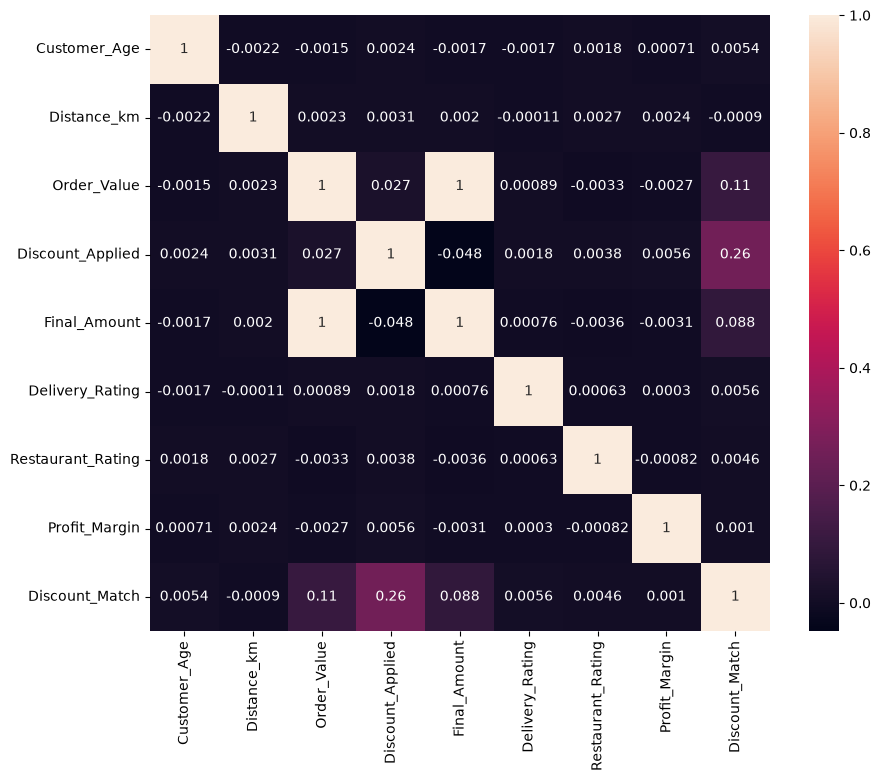

In [79]:
plt.figure(figsize=(10,8))
sns.heatmap(crr_info,annot=True)
plt.show()

#1.Distribution of order values and delivery time 

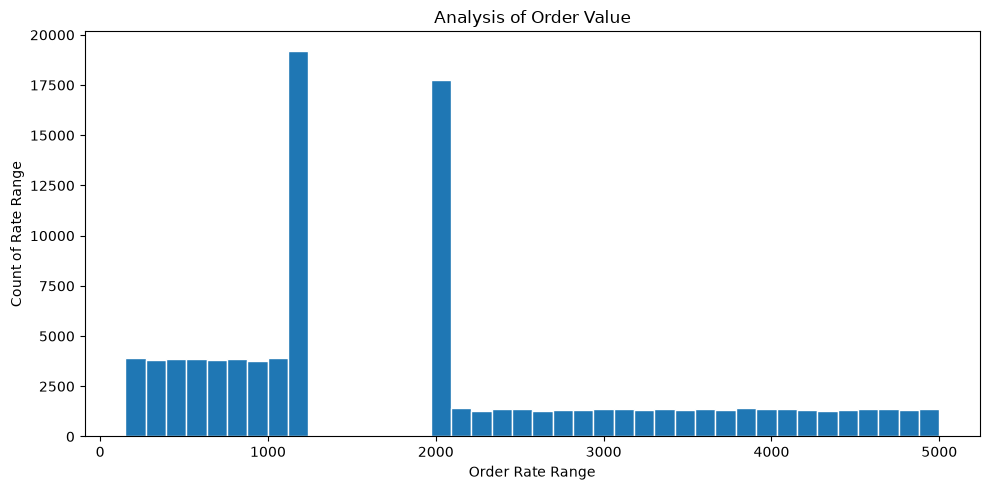

In [80]:
#1. Order Rate Range in Univariate:
o_g1=df1['Order_Value'].plot(kind='hist',bins=40,figsize=(10,5),
                             title='Analysis of Order Value',
                             edgecolor='white')
o_g1.set_xlabel('Order Rate Range')
o_g1.set_ylabel('Count of Rate Range')
plt.tight_layout()
plt.show()

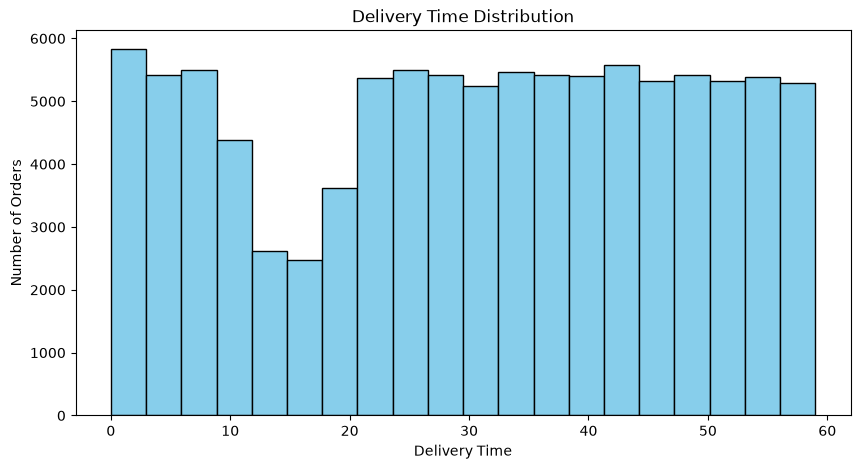

In [81]:
#2. Delivery Time Analysis(UNIVARIATE):

df1['Delivery_Minutes'] = df1['Delivery_Time'].dt.minute

del_g2 = df1['Delivery_Minutes'].plot(
    kind='hist',
    figsize=(10, 5),
    bins=20,
    color='skyblue',
    edgecolor='black'
)

plt.xlabel('Delivery Time')
plt.ylabel('Number of Orders')
plt.title('Delivery Time Distribution')
plt.show()

#2. City-wise and cuisine-wise order analysis 

In [82]:
#3. City-Area and Cusine wise:

are_ci_cu=pd.crosstab(df1['City'],df1['Area'])
are_ci_cu


Area,Central,East,North,South,West
City,,,,,
Bangalore,2738,2845,2801,5645,2703
Chennai,2727,2699,2827,5478,2739
Delhi,2699,2869,2759,5576,2792
Hyderabad,5710,5543,5589,11168,5600
Mumbai,2745,2687,2699,5543,2819


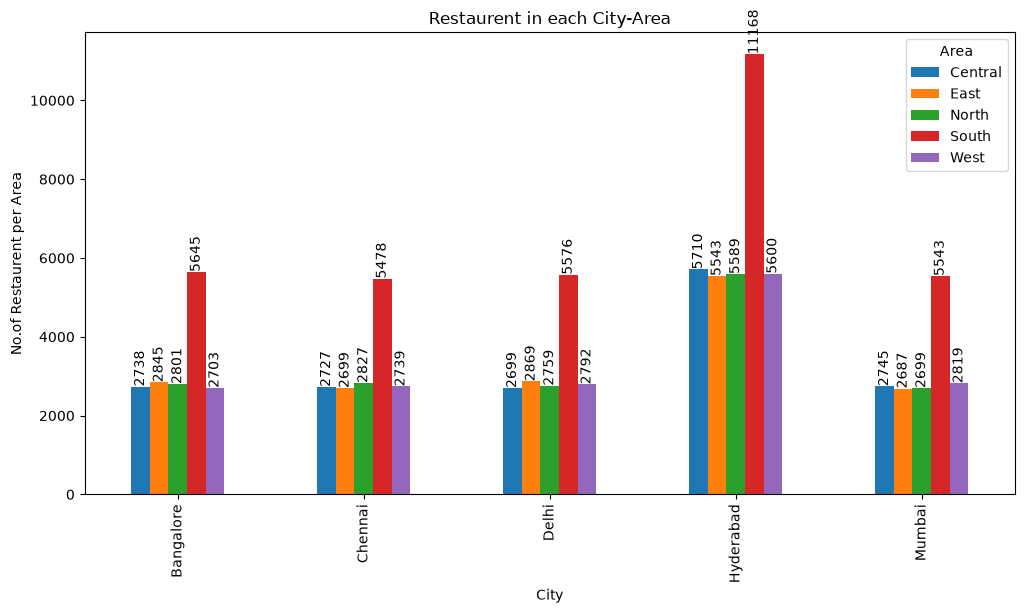

In [83]:
acc=are_ci_cu.plot(kind='bar',figsize=(12,6))

for container in acc.containers:
    acc.bar_label(container,rotation=90)
plt.title('Restaurent in each City-Area')
plt.xlabel('City')
plt.ylabel('No.of Restaurent per Area')
plt.show()


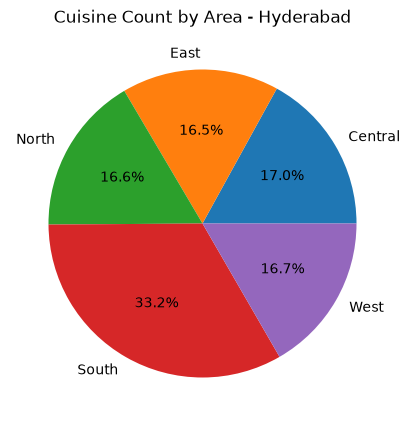

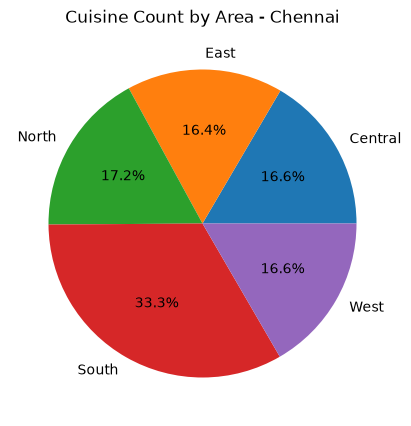

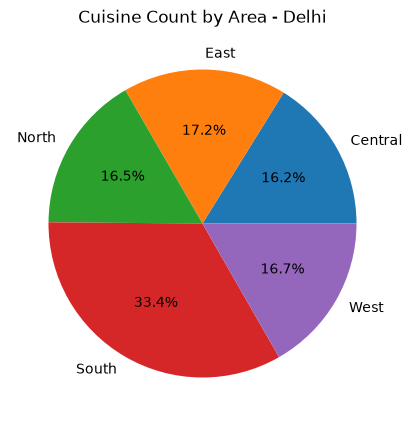

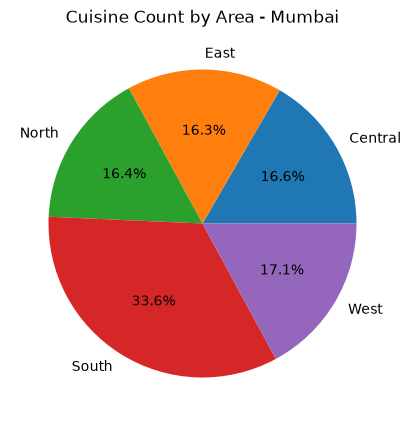

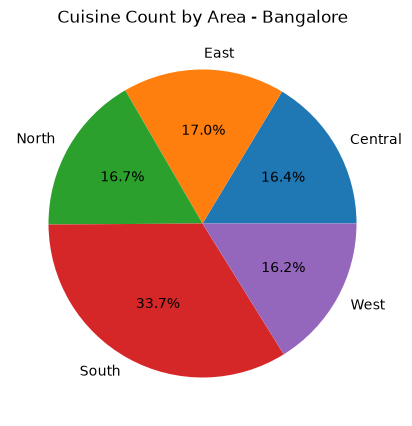

In [84]:
#4. City Area wise Cuisine:

cities = df1['City'].dropna().unique()

for city in cities:
    city_data = df1[df1['City'] == city]

    area_cuisine_count = city_data.groupby('Area')['Cuisine_Type'].count()

    plt.figure(figsize=(8, 5))
    plt.pie(
        area_cuisine_count,
        labels=area_cuisine_count.index,
        autopct='%1.1f%%'
    )

    plt.title(f'Cuisine Count by Area - {city}')
    plt.show()

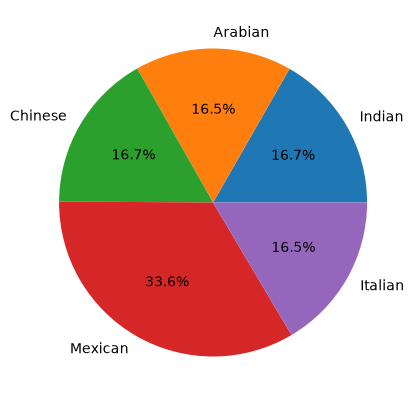

In [85]:
#over all analysis:
plt.figure(figsize=(10,5))
plt.pie(x=df1.groupby(['City'])['Area'].count(),
        labels=df1['Cuisine_Type'].value_counts().index,
        autopct='%1.1f%%')
plt.show()

In [86]:
#4. Total Restaurant in City:
res_cnt=df1.groupby('City')['Restaurant_Name'].count()

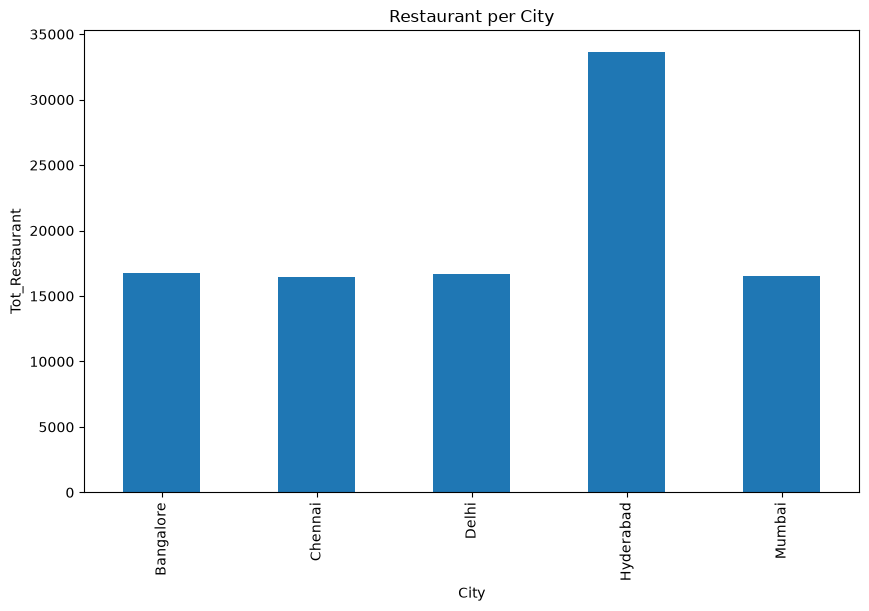

In [90]:
res_cnt.plot(kind='bar',figsize=(10,6),
             title='Restaurant per City')
plt.xlabel('City')
plt.ylabel('Tot_Restaurant')
plt.show()

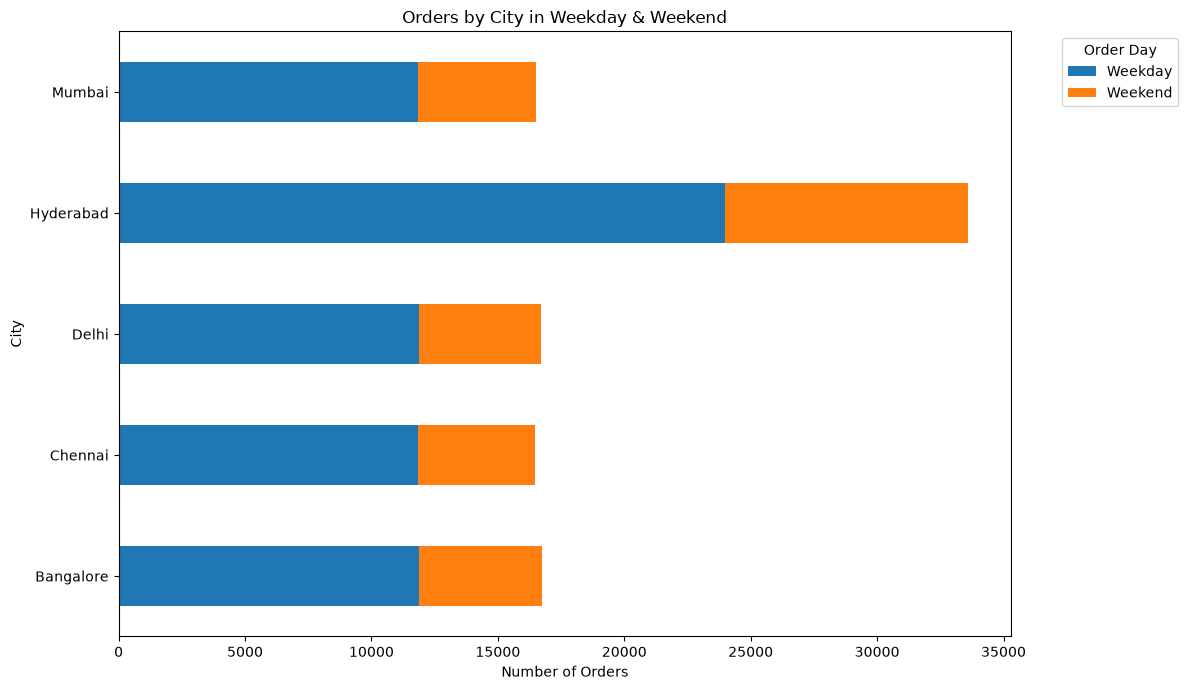

In [91]:
#5.. Weekend & Weekday Demand:
or_c = df1.groupby(['City', 'Order_Day']).size().unstack(fill_value=0)

or_c.plot(
    kind='barh',
    stacked=True,
    figsize=(12, 7)
)

plt.xlabel('Number of Orders')
plt.ylabel('City')
plt.title('Orders by City in Weekday & Weekend')
plt.legend(title='Order Day', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

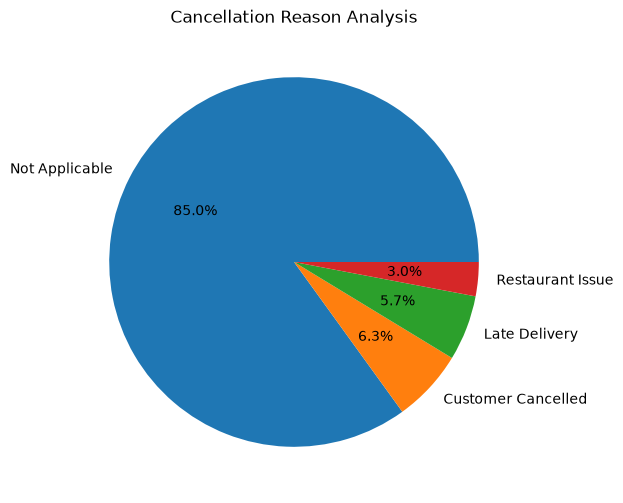

In [92]:
#6. Cancellation Reason:

plt.figure(figsize=(12,6))
plt.pie(x=df1['Cancellation_Reason'].value_counts().values,
        labels=df1['Cancellation_Reason'].value_counts().index,
        autopct='%1.1f%%')
plt.title('Cancellation Reason Analysis')
plt.show()

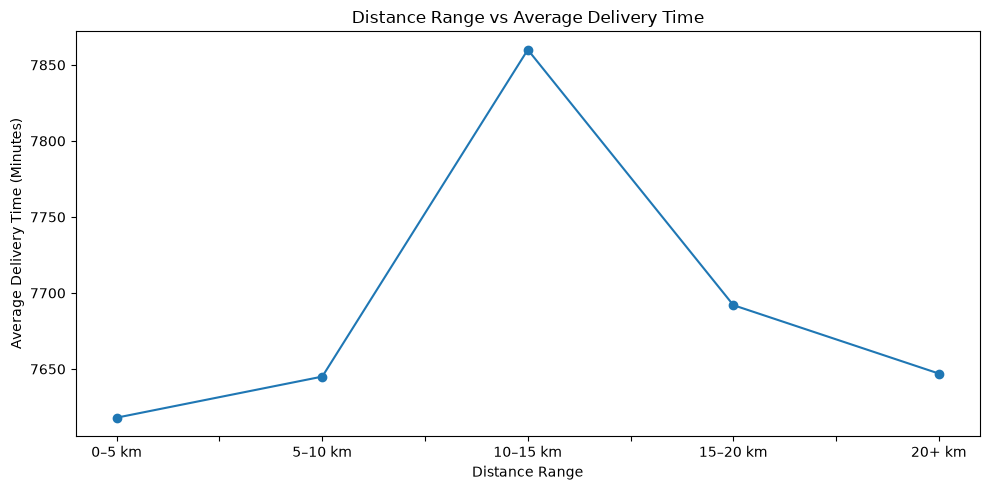

In [93]:
#7 Distance and Delivery Delay Analysis:

"""
dist=df1.groupby(['Distance_km','Delivery_Time_Min'], as_index='False')['Distance_km'].mean()
plt.figure(figsize=(20,15))
sns.lineplot(data=df1,x='Distance_km',y='Delivery_Time_Min')
plt.title('Distance VS Delivery Time')
plt.xlabel('Distance_km')
plt.ylabel('Delivery_Time')
plt.show()"""

df1['Distance_Range'] = pd.cut(
    df1['Distance_km'],
    bins=[0, 5, 10, 15, 20, float('inf')],
    labels=['0–5 km', '5–10 km', '10–15 km', '15–20 km', '20+ km'],
    include_lowest=True
)

dist = df1.groupby('Distance_Range', observed=False)['Delivery_Time_Min'].mean()

dist.plot(kind='line', marker='o', figsize=(10, 5))

plt.title('Distance Range vs Average Delivery Time')
plt.xlabel('Distance Range')
plt.ylabel('Average Delivery Time (Minutes)')
plt.tight_layout()
plt.show()

# Feature Engg:

In [94]:
#1. Profit Margin Percentage:

df1['Pro_Mar_Per']=df1['Profit_Margin']*100

In [95]:
#2. Delivery Performance Category:

cond=[
    (df1.Delivery_Rating >= 4.5),
    (df1.Delivery_Rating >=3.5)&(df1.Delivery_Rating < 4.5),
    (df1.Delivery_Rating >= 2.5)&(df1.Delivery_Rating < 3.5),
    (df1.Delivery_Rating >=1.5)&(df1.Delivery_Rating < 2.5),
    (df1.Delivery_Rating >=1)&(df1.Delivery_Rating < 1.5)
]

df1['Del_Perf']=np.select(cond,['Excellent','Good','Satisfied','Poor','Worst'],
                          default='None')

In [96]:
#3. Customer Age Group:

cond=[
    (df1.Customer_Age > 59),
    (df1.Customer_Age >= 20)&(df1.Customer_Age <=59),
    (df1.Customer_Age >= 13)&(df1.Customer_Age <20),
    (df1.Customer_Age >= 12)&(df1.Customer_Age < 13)
]

df1['Cust_Age_Group']=np.select(cond,['Elder','Adult','Teenage','Child'],
                                default="None")

In [98]:
df1.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Payment_Mode', 'Order_Status',
       'Cancellation_Reason', 'Delivery_Partner_ID', 'Delivery_Rating',
       'Restaurant_Rating', 'Order_Day', 'Peak_Hour', 'Profit_Margin',
       'Delivery_Time', 'Discount_Match', 'Delivery_Minutes', 'Distance_Range',
       'Pro_Mar_Per', 'Del_Perf', 'Cust_Age_Group'],
      dtype='str')

In [99]:
df1

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,Delivery_Time_Min,Distance_km,Order_Value,Discount_Applied,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin,Delivery_Time,Discount_Match,Delivery_Minutes,Distance_Range,Pro_Mar_Per,Del_Perf,Cust_Age_Group
0,ORD000001,CUST6948,19,Male,Hyderabad,Central,RES936,Restaurant_29,Chinese,2024-10-20,0 days 03:07:00,15.75,1197.0,50.0,1147.0,UPI,Delivered,Not Applicable,DP563,5.0,4.4,Weekend,True,0.13,2026-10-21 03:07:00,False,7,15–20 km,13.0,Excellent,Teenage
1,ORD000002,CUST6515,38,Female,Chennai,North,RES689,Restaurant_419,Chinese,2024-08-12,0 days 00:20:00,29.50,4869.0,20.0,4849.0,COD,Delivered,Not Applicable,DP369,5.0,4.7,Weekday,True,0.48,2026-10-21 00:20:00,True,20,20+ km,48.0,Excellent,Adult
2,ORD000003,CUST1765,38,Male,Delhi,South,RES723,Restaurant_244,Arabian,2024-12-08,0 days 03:27:00,9.91,757.0,20.0,737.0,Wallet,Delivered,Not Applicable,DP580,4.0,4.9,Weekend,True,0.08,2026-10-21 03:27:00,True,27,5–10 km,8.0,Good,Adult
3,ORD000004,CUST2744,38,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,2024-10-08,0 days 02:23:00,15.68,1197.0,50.0,1147.0,UPI,Cancelled,Late Delivery,DP155,2.0,3.4,Weekday,True,0.04,2026-10-21 02:23:00,False,23,15–20 km,4.0,Poor,Adult
4,ORD000005,CUST4389,57,Female,Chennai,South,RES419,Restaurant_262,Chinese,2024-02-04,0 days 00:51:00,9.60,372.0,20.0,352.0,Card,Delivered,Not Applicable,DP728,2.0,4.4,Weekend,False,0.12,2026-10-21 00:51:00,True,51,5–10 km,12.0,Poor,Adult
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,ORD099996,CUST3722,38,Female,Mumbai,South,RES295,Restaurant_500,Arabian,2024-06-10,0 days 00:46:00,15.13,232.0,100.0,132.0,Card,Delivered,Not Applicable,DP835,2.0,4.0,Weekday,True,0.17,2026-10-21 00:46:00,True,46,15–20 km,17.0,Poor,Adult
99996,ORD099997,CUST6158,38,Male,Mumbai,East,RES157,Restaurant_458,Arabian,2024-04-22,0 days 00:46:00,15.13,1098.0,20.0,1078.0,Card,Delivered,Not Applicable,DP476,4.0,3.5,Weekday,False,-0.15,2026-10-21 00:46:00,True,46,15–20 km,-15.0,Good,Adult
99997,ORD099998,CUST2155,38,Male,Delhi,East,RES287,Restaurant_273,Indian,2024-02-23,0 days 00:34:00,18.57,2003.0,20.0,1983.0,COD,Cancelled,Late Delivery,DP577,2.0,4.0,Weekday,True,0.47,2026-10-21 00:34:00,False,34,15–20 km,47.0,Poor,Adult
99998,ORD099999,CUST3015,38,Female,Delhi,North,RES491,Restaurant_241,Indian,2024-12-10,0 days 01:05:00,3.77,2003.0,100.0,1903.0,Card,Delivered,Not Applicable,DP896,3.0,4.3,Weekday,True,0.44,2026-10-21 01:05:00,False,5,0–5 km,44.0,Satisfied,Adult


In [100]:
# Changing 'Delivery_Time_Min':
df1['Delivery_Time_Min'] = (
    pd.to_timedelta(df1['Delivery_Time_Min'])
    .apply(lambda x: str(x).split()[-1])
)

In [101]:
df1.shape

(100000, 31)

In [103]:
# SAVE THE CLEANED FEATURE DATA:
df1.to_csv(
    r"D:\DS Course\Food_Delivery_P2\food_del_clean_data_fea1.csv",
    index=False,
    encoding="utf-8"
)

print("Featured Cleaned CSV saved successfully")

Featured Cleaned CSV saved successfully


In [104]:
df1.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Payment_Mode', 'Order_Status',
       'Cancellation_Reason', 'Delivery_Partner_ID', 'Delivery_Rating',
       'Restaurant_Rating', 'Order_Day', 'Peak_Hour', 'Profit_Margin',
       'Delivery_Time', 'Discount_Match', 'Delivery_Minutes', 'Distance_Range',
       'Pro_Mar_Per', 'Del_Perf', 'Cust_Age_Group'],
      dtype='str')

In [105]:
df[['Distance_km','Delivery_Time_Min']]

,Distance_km,Delivery_Time_Min
0,15.75,187.0
1,29.50,20.0
2,NaN,207.0
3,15.68,143.0
4,9.60,51.0
...,...,...
99995,NaN,NaN
99996,NaN,46.0
99997,18.57,34.0
99998,3.77,65.0


In [110]:
df[['Order_Status','Cancellation_Reason']].value_counts()

Order_Status  Cancellation_Reason
Cancelled     Late Delivery          3059
              Customer Cancelled     2993
              Restaurant Issue       2979
Name: count, dtype: int64